In [64]:
##Libraries
library(harmony)
library(Signac)
library(Seurat)
library(GenomeInfoDb)
library(ggplot2)
library(patchwork)
library(data.table)
library(GenomicRanges)
library(stringr)
library(rhdf5)
library(svglite)
library(tidyr)
library(SoupX)
library(DropletUtils)
library(dplyr)
library(cowplot)
library(DoubletFinder)
library(RColorBrewer)
library(glue)

In [65]:
##Settings
plan("multicore", workers = 16)
options(future.globals.maxSize = 1000 * 1024^10)
refcode='mm10' # hg38/mm10
enable_soupx = TRUE
my36colors <- c('#53A85F', '#F1BB72', '#F3B1A0', '#D6E7A3', '#57C3F3', '#476D87', '#E95C59', '#E59CC4', '#E5D2DD', '#AB3282', '#BD956A', 
                '#8C549C', '#E0D4CA', '#C5DEBA', '#58A4C3', '#E4C755', '#AA9A59', '#E63863', '#E39A35', '#C1E6F3', '#6778AE', '#91D0BE', 
                '#B53E2B', '#712820', '#DCC1DD', '#CCE0F5', '#CCC9E6', '#625D9E', '#68A180', '#3A6963','#968175')
sample <- "KP12"
batch <- "KP"
# analysis tree root (RawMatrix/FilterMatrix/SoupxMatrix live under here);
# export DSCI_WORK_ROOT to point at your copy - repository README, "Data layout".
work_root <- Sys.getenv("DSCI_WORK_ROOT", ".")
raw_path <- glue("{Sys.getenv('FIG1_DATA', '')}/{batch}/{sample}/04.Matrix/RawMatrix")
#raw_path <- file.path(Sys.getenv("DSCI_RESULTDATA_ROOT", ""), "Workflow/W202509150012951/04.Matrix/RawMatrix")#custome path
#raw_path <- glue("{work_root}/{batch}/{sample}/RawMatrix/Mouse")#Cellline NIH3T3
#raw_path <- glue("{work_root}/{batch}/{sample}/RawMatrix/Human")#Cellline HEK293T
filt_path <- glue("{Sys.getenv('FIG1_DATA', '')}/{batch}/{sample}/04.Matrix/FilterMatrix")
#filt_path <- file.path(Sys.getenv("DSCI_RESULTDATA_ROOT", ""), "Workflow/W202509150012951/04.Matrix/FilterMatrix")#custome path
#filt_path <- glue("{work_root}/{batch}/{sample}/FilterMatrix/Mouse")#Cellline NIH3T3
#filt_path <- glue("{work_root}/{batch}/{sample}/FilterMatrix/Human")#Cellline HEK293T
bar_path <- glue("{Sys.getenv('FIG1_DATA', '')}/{batch}/{sample}/05.MergeBead/{sample}_barcodeTranslate_16.txt")
#bar_path <- file.path(Sys.getenv("DSCI_RESULTDATA_ROOT", ""), "Workflow/W202509150012951/05.MergeBead/JO13-14_barcodeTranslate_16.txt")#custome path
#bar_path <- glue("{work_root}/{batch}/{sample}/{sample}_barcodeTranslate_16.txt")#Cellline IV5 and IV6
soupx_path <- glue("{work_root}/{batch}/{sample}/SoupxMatrix")
output_path <- glue("{work_root}/{batch}/{sample}")

In [66]:
# SoupX #
#########
run_soupx <- function(toc,tod,soupx_path,rho=NULL) {
  tod <- tod[rownames(toc),]
  all <- toc
  all <- CreateSeuratObject(all)
  all <- NormalizeData(all, normalization.method = "LogNormalize", scale.factor = 10000)
  all <- FindVariableFeatures(all, selection.method = "vst", nfeatures = 2500)
  all.genes <- rownames(all)
  all <- ScaleData(all, features = all.genes)
  all <- RunPCA(all, features = VariableFeatures(all), npcs = 40, verbose = F)
  all <- FindNeighbors(all, dims = 1:30)
  all <- FindClusters(all, resolution = 0.5)
  all <- RunUMAP(all, dims = 1:30)

  matx <- all@meta.data
  
  sc = SoupChannel(tod, toc)
  sc = setClusters(sc, setNames(matx$seurat_clusters, rownames(matx)))
  sc = setContaminationFraction(sc, 0.2)
  out = adjustCounts(sc)
  DropletUtils:::write10xCounts(soupx_path, out,version="3")
}


In [67]:
###Run soupx
if (enable_soupx) {
    # 检测soupx_path是否为空文件夹
    if (length(list.files(soupx_path)) == 0) {
      toc <- Read10X(filt_path,gene.column = 1)
      bac <- Read10X(raw_path,gene.column = 1)
      valid <- read.table(bar_path,header = F)
      bac <- bac[rownames(toc),]
      bac <- bac[,which(!(colnames(bac) %in% valid$V1))]
      tod <- cbind(bac,toc)
      unlink(soupx_path,recursive=T,force=T)
      run_soupx(toc,tod,soupx_path)
      print('soupx has already!')
    } else {
        message("SoupX directory is not empty, skipping processing")
    }
} else {
    message("Skipping SoupX")
}


Centering and scaling data matrix

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 5585
Number of edges: 240699

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8767
Number of communities: 15
Elapsed time: 0 seconds


Warning message:
“UNRELIABLE VALUE: One of the ‘future.apply’ iterations (‘future_lapply-1’) unexpectedly generated random numbers without declaring so. There is a risk that those random numbers are not statistically sound and the overall results might be invalid. To fix this, specify 'future.seed=TRUE'. This ensures that proper, parallel-safe random numbers are produced via the L'Ecuyer-CMRG method. To disable this check, use 'future.seed = NULL', or set option 'future.rng.onMisuse' to "ignore".”
17:58:58 UMAP embedding parameters a = 0.9922 b = 1.112

17:58:58 Read 5585 rows and found 30 numeric columns

17:58:58 Using Annoy for neighbor search, n_neighbors = 30

17:58:58 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

17:58:59 Writing NN index file to temp file /tmp

[1] "soupx has already!"


In [ ]:
##Make RNA object
if (enable_soupx) {
    object <- Read10X(soupx_path,gene.column = 1)
    object <- CreateSeuratObject(object)
    object[["percent.mt"]] <- PercentageFeatureSet(object, pattern = "^mt-")    
} else {
    object <- Read10X(filt_path,gene.column = 1)
    object <- CreateSeuratObject(object)
    object[["percent.mt"]] <- PercentageFeatureSet(object, pattern = "^mt-")
}  

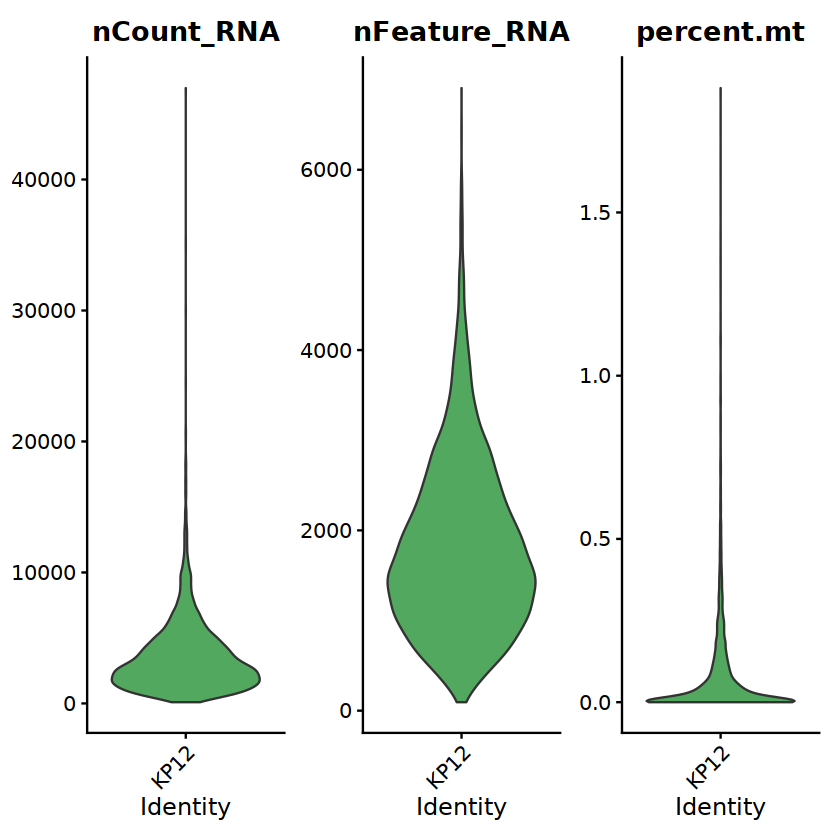

In [ ]:
#QC plot after soupx
p1=VlnPlot(object,c('nCount_RNA','nFeature_RNA','percent.mt'),group.by='orig.ident',pt.size = 0,cols = my36colors,raster = FALSE)
p1

In [ ]:
if (enable_soupx) {
    ggsave(glue("{output_path}/{sample}_QC_RNA_soupx.pdf"),p1,height = 8,width = 12)
} else {
    ggsave(glue("{output_path}/{sample}_QC_RNA.pdf"),p1,height = 8,width = 12)
}

In [ ]:
## DoubletFilter 10% ##
Find_doublet <- function(data){
  sweep.res.list <- paramSweep_v3(data, PCs = 1:30, sct = F)
  sweep.stats <- summarizeSweep(sweep.res.list, GT = FALSE)
  bcmvn <- find.pK(sweep.stats)
  nExp_poi <- round(0.1*ncol(data)) ## choose filter rate
  p<-as.numeric(as.vector(bcmvn[bcmvn$MeanBC==max(bcmvn$MeanBC),]$pK))
  data <- doubletFinder_v3(data, PCs = 1:30, pN = 0.25, pK = p, nExp = nExp_poi, reuse.pANN = FALSE, sct = F)
  colnames(data@meta.data)[ncol(data@meta.data)] = "doublet_info"
  #data<-subset(data,subset=doublet_info=="Singlet")
  data
}

Centering and scaling data matrix

PC_ 1 
Positive:  Mertk, Slc1a3, Apbb1ip, Fyb, Qk, Lrmda, Neat1, Lyn, Inpp5d, Dock2 
	   Msr1, Cd84, Abca1, Dab2, Adap2, Tns3, Apobec1, Ly86, Fcrls, Zbtb20 
	   Rnf213, Ikzf1, AU020206, Fli1, Plpp3, Tcf7l2, Anxa3, Dock1, Atp1a2, Tgfbr1 
Negative:  Meg3, Gria1, AC149090.1, Asic2, Dpp6, Dab1, Cntnap2, Slit3, Chrm3, Frmpd4 
	   Etl4, Lrrtm4, Schip1, Nrg1, Peg3, Epha6, Cntn5, Cntnap5a, Brinp1, Sphkap 
	   Hs6st3, Gabrg3, Ryr3, Car10, Unc5d, Cplane1, Srrm3, Cdh8, Grm1, Pdzrn3 
PC_ 2 
Positive:  Slc1a3, Ptprz1, Atp1a2, Prex2, Msi2, Zbtb20, Nhsl1, Plpp3, Npas3, Gpc5 
	   Slc1a2, Luzp2, Fam107a, Slco1c1, Gli3, Arhgef26, Htra1, Ccdc141, Glul, Sox6 
	   Acsl3, Nwd1, Id4, Rgs20, Nckap5, Slc4a4, Gja1, Grin2c, F3, Slc39a12 
Negative:  Apbb1ip, Inpp5d, Fyb, Msr1, Cd84, Cmss1, Lyn, Ly86, Dock2, Fcrls 
	   Adap2, AU020206, Ifi207, Ikzf1, Mir142hg, Cd180, Vav1, Lilrb4a, Gm2629, Fli1 
	   Itgam, Dab2, Cx3cr1, Trim30a, Lrmda, Apobec1, Kcnk13, Spp1, Cyth4, Bin2 
PC_ 3 
P

[1] "Creating artificial doublets for pN = 5%"
[1] "Creating Seurat object..."
[1] "Normalizing Seurat object..."
[1] "Finding variable genes..."
[1] "Scaling data..."


Centering and scaling data matrix



[1] "Running PCA..."
[1] "Calculating PC distance matrix..."
[1] "Defining neighborhoods..."
[1] "Computing pANN across all pK..."
[1] "pK = 0.005..."
[1] "pK = 0.01..."
[1] "pK = 0.02..."
[1] "pK = 0.03..."
[1] "pK = 0.04..."
[1] "pK = 0.05..."
[1] "pK = 0.06..."
[1] "pK = 0.07..."
[1] "pK = 0.08..."
[1] "pK = 0.09..."
[1] "pK = 0.1..."
[1] "pK = 0.11..."
[1] "pK = 0.12..."
[1] "pK = 0.13..."
[1] "pK = 0.14..."
[1] "pK = 0.15..."
[1] "pK = 0.16..."
[1] "pK = 0.17..."
[1] "pK = 0.18..."
[1] "pK = 0.19..."
[1] "pK = 0.2..."
[1] "pK = 0.21..."
[1] "pK = 0.22..."
[1] "pK = 0.23..."
[1] "pK = 0.24..."
[1] "pK = 0.25..."
[1] "pK = 0.26..."
[1] "pK = 0.27..."
[1] "pK = 0.28..."
[1] "pK = 0.29..."
[1] "pK = 0.3..."
[1] "Creating artificial doublets for pN = 10%"
[1] "Creating Seurat object..."
[1] "Normalizing Seurat object..."
[1] "Finding variable genes..."
[1] "Scaling data..."


Centering and scaling data matrix



[1] "Running PCA..."
[1] "Calculating PC distance matrix..."
[1] "Defining neighborhoods..."
[1] "Computing pANN across all pK..."
[1] "pK = 0.005..."
[1] "pK = 0.01..."
[1] "pK = 0.02..."
[1] "pK = 0.03..."
[1] "pK = 0.04..."
[1] "pK = 0.05..."
[1] "pK = 0.06..."
[1] "pK = 0.07..."
[1] "pK = 0.08..."
[1] "pK = 0.09..."
[1] "pK = 0.1..."
[1] "pK = 0.11..."
[1] "pK = 0.12..."
[1] "pK = 0.13..."
[1] "pK = 0.14..."
[1] "pK = 0.15..."
[1] "pK = 0.16..."
[1] "pK = 0.17..."
[1] "pK = 0.18..."
[1] "pK = 0.19..."
[1] "pK = 0.2..."
[1] "pK = 0.21..."
[1] "pK = 0.22..."
[1] "pK = 0.23..."
[1] "pK = 0.24..."
[1] "pK = 0.25..."
[1] "pK = 0.26..."
[1] "pK = 0.27..."
[1] "pK = 0.28..."
[1] "pK = 0.29..."
[1] "pK = 0.3..."
[1] "Creating artificial doublets for pN = 15%"
[1] "Creating Seurat object..."
[1] "Normalizing Seurat object..."
[1] "Finding variable genes..."
[1] "Scaling data..."


... (6 outputs left out)

Centering and scaling data matrix



[1] "Running PCA..."
[1] "Calculating PC distance matrix..."
[1] "Defining neighborhoods..."
[1] "Computing pANN across all pK..."
[1] "pK = 0.005..."
[1] "pK = 0.01..."
[1] "pK = 0.02..."
[1] "pK = 0.03..."
[1] "pK = 0.04..."
[1] "pK = 0.05..."
[1] "pK = 0.06..."
[1] "pK = 0.07..."
[1] "pK = 0.08..."
[1] "pK = 0.09..."
[1] "pK = 0.1..."
[1] "pK = 0.11..."
[1] "pK = 0.12..."
[1] "pK = 0.13..."
[1] "pK = 0.14..."
[1] "pK = 0.15..."
[1] "pK = 0.16..."
[1] "pK = 0.17..."
[1] "pK = 0.18..."
[1] "pK = 0.19..."
[1] "pK = 0.2..."
[1] "pK = 0.21..."
[1] "pK = 0.22..."
[1] "pK = 0.23..."
[1] "pK = 0.24..."
[1] "pK = 0.25..."
[1] "pK = 0.26..."
[1] "pK = 0.27..."
[1] "pK = 0.28..."
[1] "pK = 0.29..."
[1] "pK = 0.3..."
NULL
[1] "Creating 1854 artificial doublets..."
[1] "Creating Seurat object..."
[1] "Normalizing Seurat object..."
[1] "Finding variable genes..."
[1] "Scaling data..."


Centering and scaling data matrix



[1] "Running PCA..."
[1] "Calculating PC distance matrix..."
[1] "Computing pANN..."
[1] "Classifying doublets.."


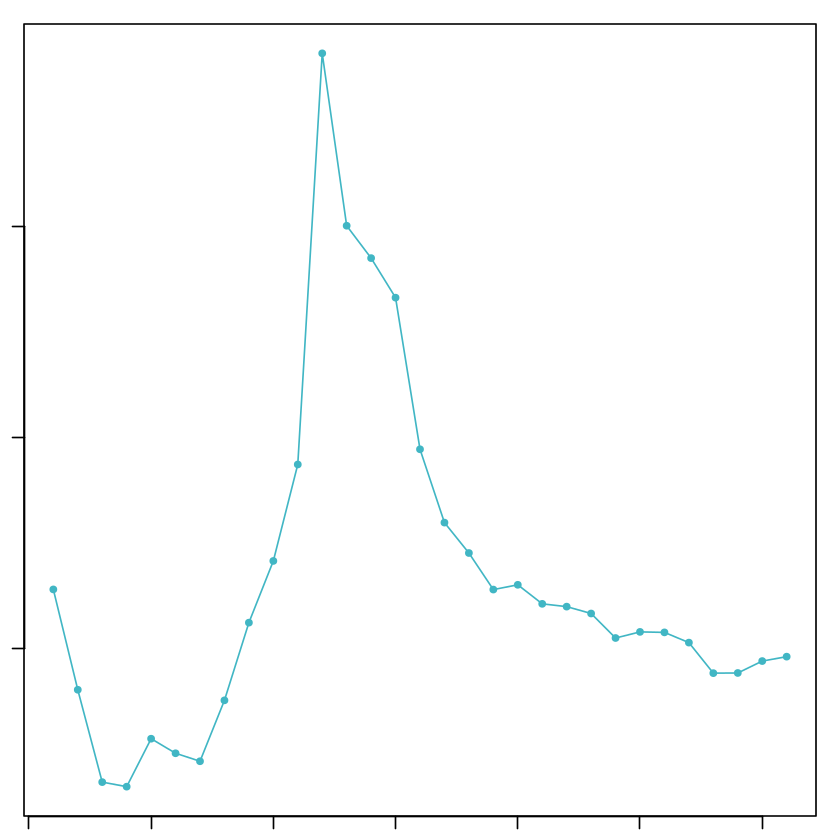

In [73]:
#PCA, doublet finding and normalization
#object <- subset(object,percent.mt<20 & nCount_RNA<100000 & nCount_RNA>200 & nFeature_RNA<7500)#From ZZJ,defult
object <- subset(object,percent.mt<20 & nCount_RNA<20000 & nFeature_RNA>200 & nFeature_RNA<6000)#JM14,20250715
object <- NormalizeData(object)
object <- FindVariableFeatures(object, selection.method = "vst", nfeatures = 3000)
object <- ScaleData(object, features = VariableFeatures(object))
object <- RunPCA(object, features = VariableFeatures(object))
object <- Find_doublet(object)
object <- subset(object,subset=doublet_info=="Singlet")
object <- NormalizeData(object)
object <- FindVariableFeatures(object, selection.method = "vst", nfeatures = 3000)

In [ ]:
rna <- object
table(rna@meta.data$orig.ident)
cell_count <- nrow(rna@meta.data)


KP12 
5006 

In [ ]:
if (enable_soupx) {
    write(cell_count,file = glue("{output_path}/{sample}_cellnum_RNA_soupx.txt"))
} else {
    write(cell_count,file = glue("{output_path}/{sample}_cellnum_RNA.txt"))
}

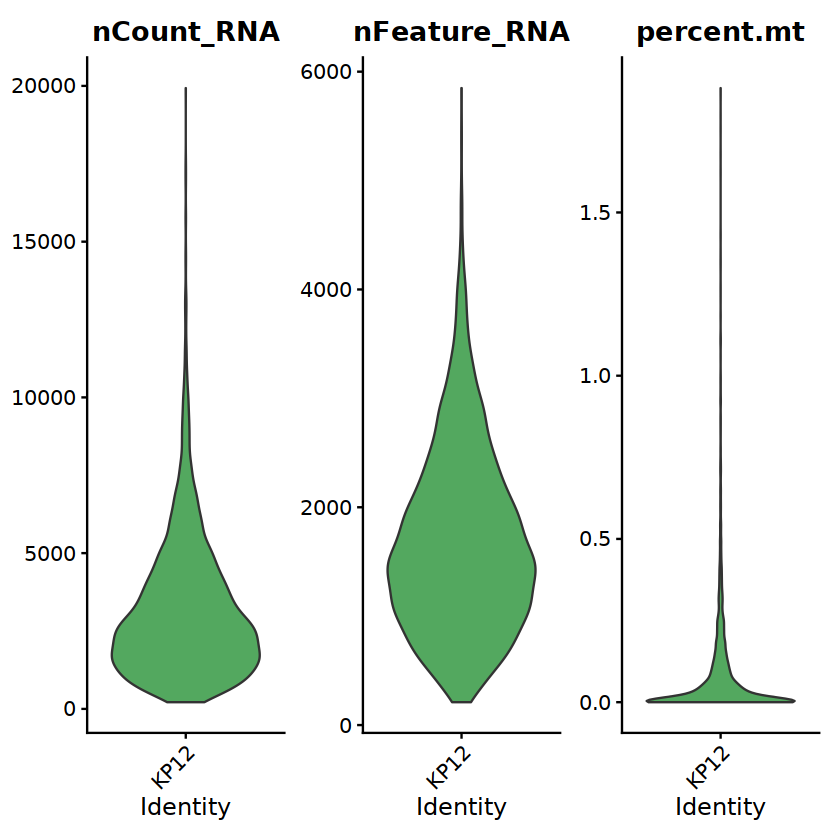

In [ ]:
p2=VlnPlot(rna,c('nCount_RNA','nFeature_RNA','percent.mt'),group.by='orig.ident',pt.size = 0,cols = my36colors,raster = FALSE)
p2

In [ ]:
if (enable_soupx) {
    ggsave(glue("{output_path}/{sample}_subset_QC_RNA_soupx.pdf"),p2,height = 8,width = 12)
} else {
    ggsave(glue("{output_path}/{sample}_subset_QC_RNA.pdf"),p2,height = 8,width = 12)
}

In [ ]:
#if (enable_soupx) {
    #saveRDS(object,glue("{output_path}/{sample}_RNA_soupx_object0715.RDS"))
#} else {
    #saveRDS(object,glue("{output_path}/{sample}_RNA_object.RDS"))
#}

In [ ]:
#rna <- readRDS(glue("{output_path}/{sample}_RNA_soupx_object.RDS"))

Centering and scaling data matrix



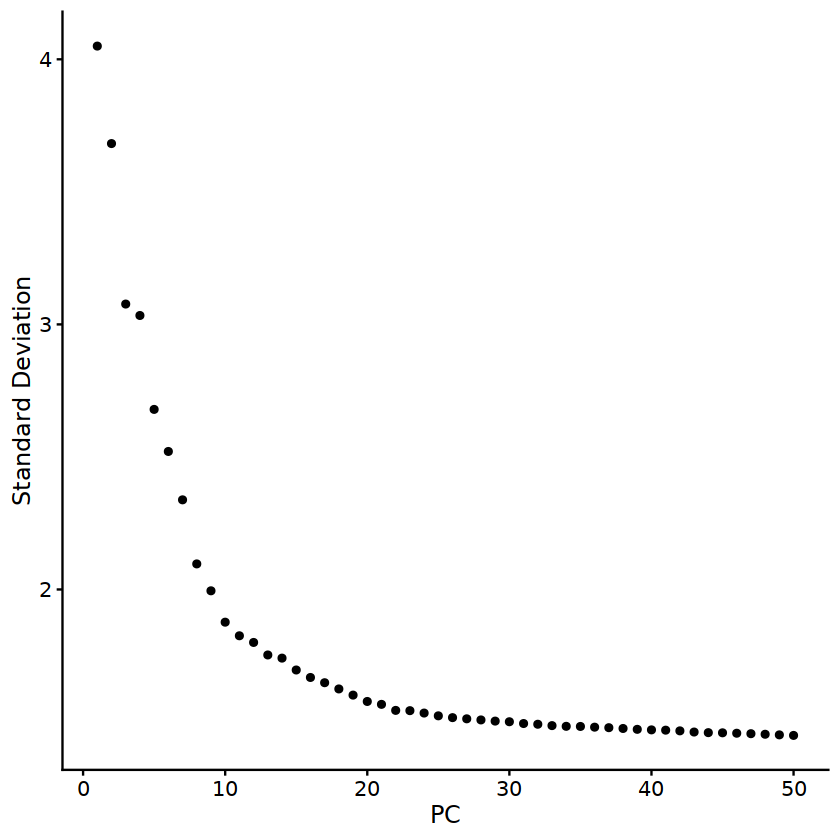

In [ ]:
#PCA
rna <- NormalizeData(rna,normalization.method = "LogNormalize")
rna <- FindVariableFeatures(rna,selection.method = "vst",nfeatures = 3000)
rna <- ScaleData(rna)
rna <- RunPCA(rna,verbose = F)
p3=ElbowPlot(rna,ndims = 50)
p3

In [ ]:
if (enable_soupx) {
    ggsave(glue("{output_path}/{sample}_Elbow_RNA_soupx.pdf"),p3,height = 8,width = 12)
} else {
    ggsave(glue("{output_path}/{sample}_Elbow_QC_RNA.pdf"),p3,height = 8,width = 12)
}

In [ ]:
pc.num <- 1:30
rna <- RunUMAP(rna,reduction = "pca", dims = pc.num)
rna <- FindNeighbors(rna, reduction = "pca", dims = pc.num)
rna <- FindClusters(rna, resolution = 1)

18:10:19 UMAP embedding parameters a = 0.9922 b = 1.112

18:10:19 Read 5006 rows and found 30 numeric columns

18:10:19 Using Annoy for neighbor search, n_neighbors = 30

18:10:19 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

18:10:20 Writing NN index file to temp file /tmp/RtmpBI6Kse/filecc28dbce1c

18:10:20 Searching Annoy index using 16 threads, search_k = 3000

18:10:20 Annoy recall = 100%

18:10:22 Commencing smooth kNN distance calibration using 16 threads
 with target n_neighbors = 30

18:10:26 Initializing from normalized Laplacian + noise (using irlba)

18:10:26 Commencing optimization for 500 epochs, with 223564 positive edges

18:10:49 Optimization finished

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 5006
Number of edges: 227723

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8333
Number of communities: 18
Elapsed time: 0 seconds


Warning message:
“UNRELIABLE VALUE: One of the ‘future.apply’ iterations (‘future_lapply-1’) unexpectedly generated random numbers without declaring so. There is a risk that those random numbers are not statistically sound and the overall results might be invalid. To fix this, specify 'future.seed=TRUE'. This ensures that proper, parallel-safe random numbers are produced via the L'Ecuyer-CMRG method. To disable this check, use 'future.seed = NULL', or set option 'future.rng.onMisuse' to "ignore".”


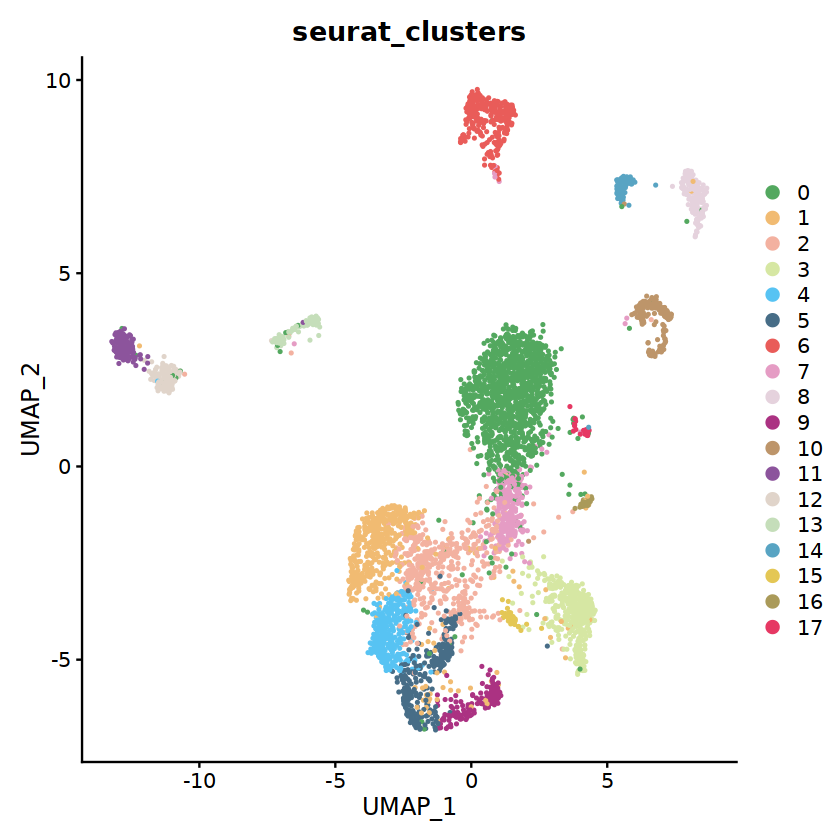

In [ ]:
p4=DimPlot(rna,reduction = "umap", group.by = "seurat_clusters", pt.size = 0.4,shuffle = T,cols = my36colors)
p4

In [ ]:
if (enable_soupx) {
    ggsave(glue("{output_path}/{sample}_cluster_RNA_soupx.pdf"),p4,height = 8,width = 8)
} else {
    ggsave(glue("{output_path}/{sample}_cluster_QC_RNA.pdf"),p4,height = 8,width = 8)
}

In [ ]:
if (enable_soupx) {
    saveRDS(rna,glue("{output_path}/{sample}_RNA_soupx_PCA.RDS"))
} else {
    saveRDS(rna,glue("{output_path}/{sample}_RNA_PCA.RDS"))
}